# CAPE-V Ratings Calibration

In [11]:
import pandas as pd
import yaml
import os
import sys
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

project_root = os.path.abspath("..")
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from paths import CONFIG_PATH

with open(CONFIG_PATH, encoding="utf-8") as config_file:
    config = yaml.safe_load(config_file)

raw_feature_path = Path(config["paths"]["ratings"])
feature_path = (
    raw_feature_path
    if raw_feature_path.is_absolute()
    else Path(project_root) / raw_feature_path
)
os.makedirs(feature_path, exist_ok=True)
                    
FILES = {                                  
    "Loudness": "cape_v_loudness_only.xlsx",
    "Pitch":    "cape_v_pitch_only.xlsx",
    "Severity": "cape_v_severity_only.xlsx",
    "Breathiness": "cape_v_breathiness_only.xlsx",
    "Strain": "cape_v_strain_only.xlsx",
    "Roughness": "cape_v_roughness_only.xlsx",
}

RATERS = [1, 2, 3, 4]
FULL, PARTIAL = ["Rater 1", "Rater 2", "Rater 3"], "Rater 4"

## 1. Load the data

In [12]:
def load_criterion(path, name):
    raw = pd.read_excel(path)
    raw.columns = raw.columns.str.strip()
    raw["File"] = raw["File"].astype(str).str.strip()

    #we compile all of our data into a single database
    parts = []
    for r in RATERS:
        for t in (1, 2):
            col = next(c for c in raw.columns if c.lower() == f"rater {r} time {t}")
            parts.append(
                pd.DataFrame({
                    "criterion": name,
                    "File": raw["File"],
                    "rater": f"Rater {r}",
                    "time": t,
                    "rating": pd.to_numeric(raw[col], errors="coerce"),
                })
            )
    return pd.concat(parts, ignore_index=True).dropna(subset=["rating"])


base_dir = Path(feature_path)
long = pd.concat([load_criterion(base_dir / f, n) for n, f in FILES.items()],ignore_index=True,)
long

,criterion,File,rater,time,rating
0,Loudness,BL01,Rater 1,1,6.0
1,Loudness,BL02,Rater 1,1,40.0
2,Loudness,BL03,Rater 1,1,44.0
3,Loudness,BL04,Rater 1,1,10.0
4,Loudness,BL05,Rater 1,1,7.0
...,...,...,...,...,...
11239,Roughness,SJ6005,Rater 4,2,40.0
11240,Roughness,SJ6006,Rater 4,2,3.0
11241,Roughness,SJ6007,Rater 4,2,11.0
11242,Roughness,SJ6008,Rater 4,2,1.0


In [13]:
#we would like to have the list of recordings that have ratings from all 4 raters for later use
CRITERIA, RATER_ORDER = list(FILES), [f"Rater {r}" for r in RATERS]

n_r = long.groupby(["criterion", "File"])["rater"].nunique().rename("n").reset_index()
common = n_r[n_r["n"] == 4][["criterion", "File"]]
long_common = long.merge(common, on=["criterion", "File"])
long_common

,criterion,File,rater,time,rating
0,Loudness,SJ2015,Rater 1,1,0.0
1,Loudness,SJ2016,Rater 1,1,0.0
2,Loudness,SJ2017,Rater 1,1,0.0
3,Loudness,SJ30001,Rater 1,1,0.0
4,Loudness,SJ30002,Rater 1,1,0.0
...,...,...,...,...,...
2347,Roughness,SJ6005,Rater 4,2,40.0
2348,Roughness,SJ6006,Rater 4,2,3.0
2349,Roughness,SJ6007,Rater 4,2,11.0
2350,Roughness,SJ6008,Rater 4,2,1.0


In [14]:
#merge both times together by taking the average and pivot
rater_file = (long.groupby(["criterion", "File", "rater"], as_index=False)["rating"].mean())
wide = rater_file.pivot_table(index=["criterion", "File"], columns="rater", values="rating")

#we would like to look at the bias some raters might have in order to correct it
rows = []
for (crit, f), r in wide.iterrows():
    for rater in RATER_ORDER:
        if pd.notna(r[rater]):
            others = r.drop(rater).dropna()
            if len(others):
                #add mean of other raters and difference between rater and others
                rows.append((crit, f, rater, r[rater], others.mean(), r[rater] - others.mean()))
bias = pd.DataFrame(rows, columns=["criterion", "File", "rater", "score", "others_mean", "diff"])
bias.head()

,criterion,File,rater,score,others_mean,diff
0,Breathiness,BL01,Rater 1,9.0,2.25,6.75
1,Breathiness,BL01,Rater 2,1.0,6.25,-5.25
2,Breathiness,BL01,Rater 3,3.5,5.00,-1.50
3,Breathiness,BL02,Rater 1,35.5,64.50,-29.00
4,Breathiness,BL02,Rater 2,48.0,58.25,-10.25


# 2. Visualize

In [15]:
#we can now look at general features of rater per category
summary = (long.groupby(["criterion", "rater"])["rating"]
           .agg(n="size", mean="mean", median="median", sd="std", p90=lambda s: s.quantile(.9))
           .round(1))
summary

n  mean  median    sd   p90
criterion   rater                                 
Breathiness Rater 1  592  22.1    11.0  26.9  68.9
            Rater 2  592  15.5     3.0  22.8  48.0
            Rater 3  592  21.2    10.0  25.8  64.0
            Rater 4   98  14.7    11.0  15.3  35.3
Loudness    Rater 1  592  20.6     7.5  27.7  69.0
            Rater 2  592  17.2     2.0  27.5  68.9
            Rater 3  592  17.6     7.0  23.9  55.9
            Rater 4   98   8.6     1.0  11.6  25.0
Pitch       Rater 1  592  16.8     5.0  24.6  53.0
            Rater 2  592  14.9     1.5  24.5  49.9
            Rater 3  592  16.7     5.0  23.2  49.0
            Rater 4   98   7.8     1.0  14.9  24.0
Roughness   Rater 1  592  24.0    16.0  24.2  62.0
            Rater 2  592  17.9     9.5  22.8  51.0
            Rater 3  592  19.8    11.0  21.6  52.0
            Rater 4   98  16.5    12.0  13.0  31.3
Severity    Rater 1  592  33.9    25.0  28.6  81.0
            Rater 2  592  26.4    18.0  26.9  69.0
            Rater 3  592  27.4    16.0  27.7  73.0
            Rater 4   98  21.3    20.5  14.1  40.0
Strain      Rater 1  592  24.3    13.0  27.2  70.8
            Rater 2  592  17.5     6.5  24.7  50.8
            Rater 3  592  21.2    11.0  24.8  61.9
            Rater 4   98  13.2    11.0  13.1  33.3

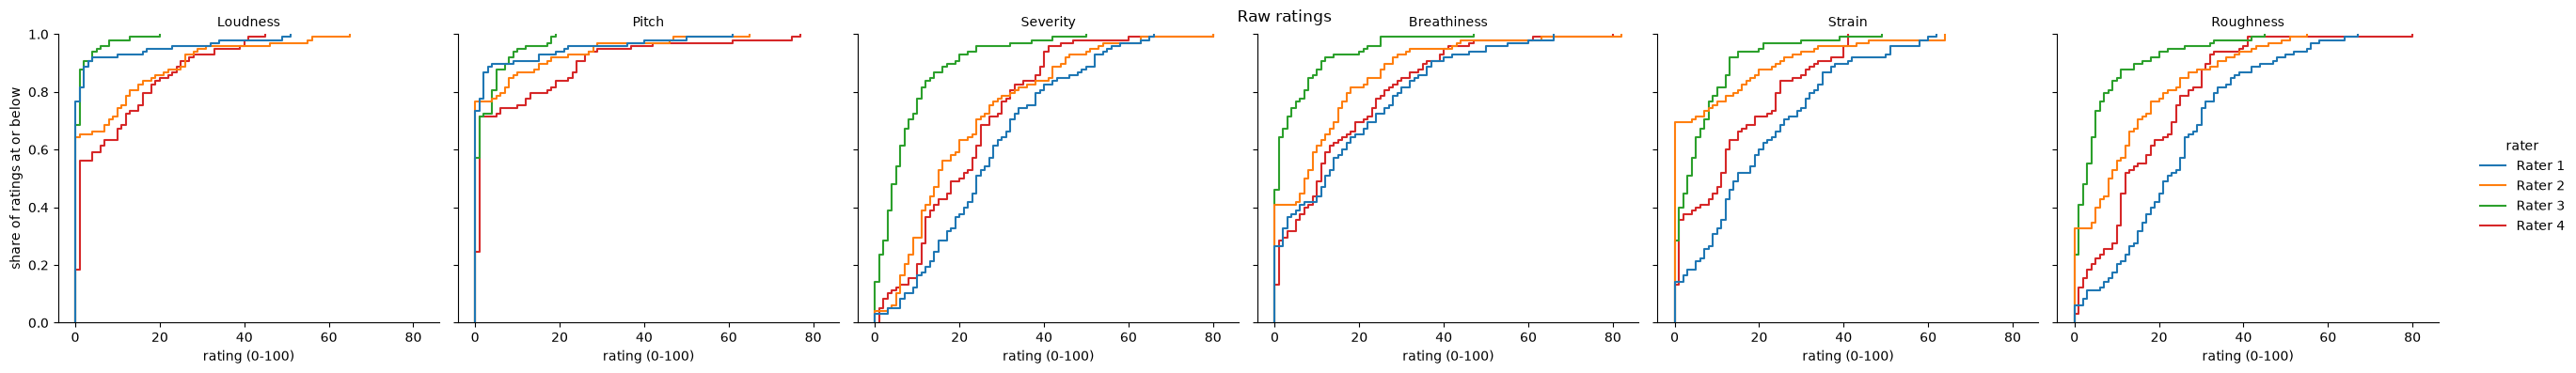

In [16]:
#display differences between raters 
g = sns.displot(data=long_common, x="rating", hue="rater", hue_order=RATER_ORDER, col="criterion",
                col_order=CRITERIA, kind="ecdf", height=4, aspect=1.1)
g.set_axis_labels("rating (0-100)", "share of ratings at or below")
g.set_titles("{col_name}")
g.figure.suptitle("Raw ratings")
plt.show()

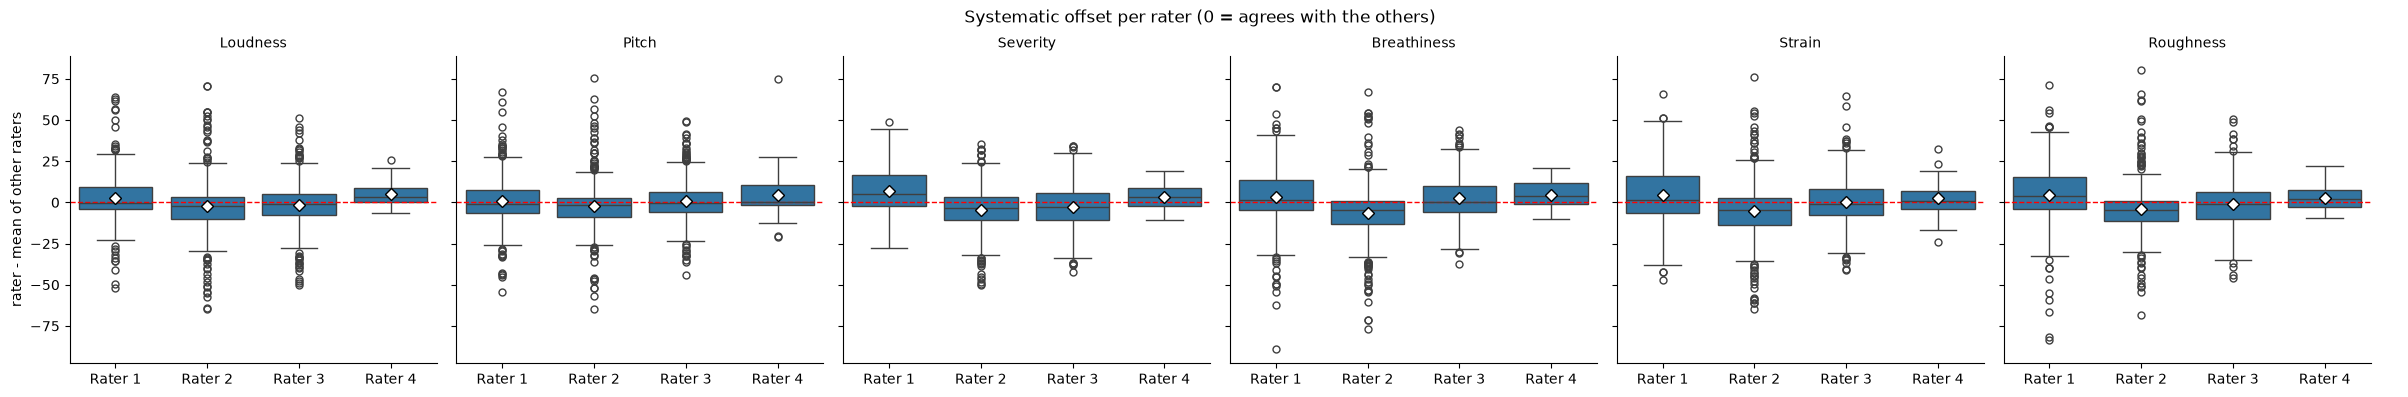

In [17]:
#display bias using box plot
g = sns.catplot(data=bias, x="rater", y="diff", col="criterion", kind="box", order=RATER_ORDER, col_order=CRITERIA,
                showmeans=True, height=4, meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black"))
for ax in g.axes.flat: ax.axhline(0, color="red", ls="--", lw=1)
g.set_axis_labels("", "rater - mean of other raters")
g.set_titles("{col_name}")
g.figure.suptitle("Systematic offset per rater (0 = agrees with the others)", y=1.03)
plt.show()

# 3. Z-Shift

In [18]:
#apply z - score on all raters
params = long.groupby(["criterion", "rater"])["rating"].agg(mu="mean", sd="std").reset_index()
zlong = long.merge(params, on=["criterion", "rater"])
zlong["z"] = (zlong["rating"] - zlong["mu"]) / zlong["sd"]

# look at full raters performance in the recordings Rater 4 rated
r4_files = long.loc[long["rater"] == PARTIAL, ["criterion", "File"]].drop_duplicates()
ref_z = (zlong[zlong["rater"].isin(FULL)].merge(r4_files, on=["criterion", "File"])
         .groupby(["criterion", "rater"])["z"].agg(["mean", "std"])
         .groupby("criterion").mean())                    

# use formula shift + scale*(rating - mu)/std on rater 4
is4 = zlong["rater"] == PARTIAL
zlong.loc[is4, "z"] = (zlong.loc[is4, "criterion"].map(ref_z["mean"])
                       + zlong.loc[is4, "criterion"].map(ref_z["std"]) * zlong.loc[is4, "z"])

# create reference to be used in exporting
ref = (params[params["rater"].isin(FULL)].groupby("criterion")[["mu", "sd"]].mean()
       .rename(columns={"mu": "ref_mu", "sd": "ref_sd"}))
params

,criterion,rater,mu,sd
0,Breathiness,Rater 1,22.054054,26.854823
1,Breathiness,Rater 2,15.494932,22.778191
2,Breathiness,Rater 3,21.234797,25.828746
3,Breathiness,Rater 4,14.724490,15.287473
4,Loudness,Rater 1,20.623311,27.688593
5,Loudness,Rater 2,17.246622,27.518460
6,Loudness,Rater 3,17.589527,23.895261
7,Loudness,Rater 4,8.602041,11.580948
8,Pitch,Rater 1,16.844595,24.591130
9,Pitch,Rater 2,14.864865,24.487062


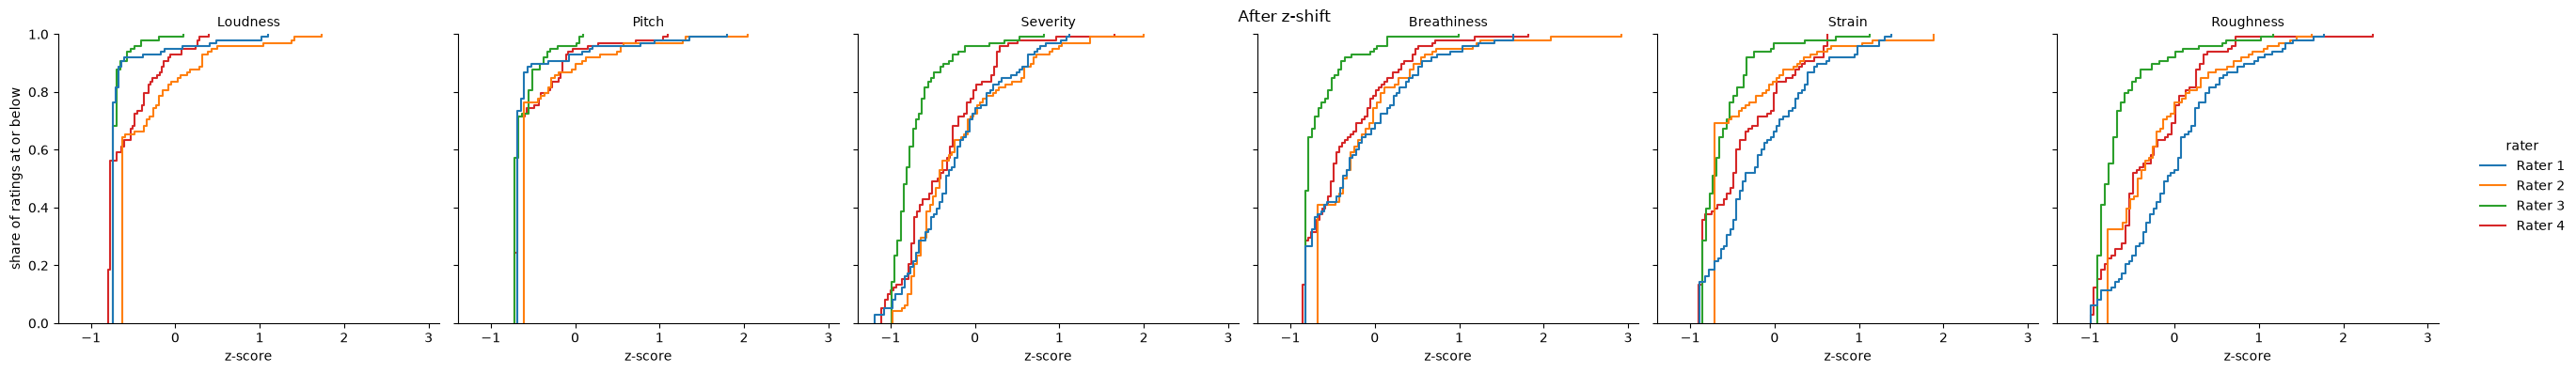

In [19]:
#we visualize the new data in the same way we did before to see if there are improvements
zc = zlong.merge(common, on=["criterion", "File"])
g = sns.displot(data=zc, x="z", hue="rater", hue_order=RATER_ORDER, col="criterion", col_order=CRITERIA,
                kind="ecdf", height=4, aspect=1.1)
g.set_axis_labels("z-score", "share of ratings at or below")
g.set_titles("{col_name}")
g.figure.suptitle("After z-shift")
plt.show()

# 4. Export

In [20]:
z_rater = zlong.groupby(["criterion", "File", "rater"], as_index=False)["z"].mean()     #here we compute an average (might be changed later)

#we use the concencus of all raters to come to a conclusion
cons = (z_rater.groupby(["criterion", "File"])["z"]
        .agg(z_consensus="mean", z_sd_between_raters="std", n_raters="size").reset_index()
        .merge(ref, on="criterion"))

# go back from z values to ratings
cons["calibrated_0_100"] = (cons["z_consensus"] * cons["ref_sd"] + cons["ref_mu"]).clip(0, 100)
cons = cons.drop(columns=["ref_mu", "ref_sd"])

#final exporting details
final = cons.pivot(index="File", columns="criterion",
                   values=["calibrated_0_100", "z_consensus", "z_sd_between_raters"])
final.columns = [f"{crit}_{metric}" for metric, crit in final.columns]
final = final.reset_index()
final.to_excel("cape_v_consensus.xlsx", index=False)
final.head()

,File,Breathiness_calibrated_0_100,Loudness_calibrated_0_100,Pitch_calibrated_0_100,Roughness_calibrated_0_100,Severity_calibrated_0_100,Strain_calibrated_0_100,Breathiness_z_consensus,Loudness_z_consensus,Pitch_z_consensus,Roughness_z_consensus,Severity_z_consensus,Strain_z_consensus,Breathiness_z_sd_between_raters,Loudness_z_sd_between_raters,Pitch_z_sd_between_raters,Roughness_z_sd_between_raters,Severity_z_sd_between_raters,Strain_z_sd_between_raters
0,BL01,4.426121,9.344649,6.244176,9.509034,14.542515,4.446291,-0.603026,-0.346709,-0.410963,-0.484409,-0.529506,-0.646993,0.104337,0.437253,0.308561,0.250778,0.314593,0.077600
1,BL02,55.159040,56.016717,36.030168,65.673930,74.047196,58.361912,1.413873,1.423355,0.825147,1.970591,1.615604,1.461991,0.906678,0.921206,0.298036,0.780866,0.556462,0.541608
2,BL03,33.116027,38.085733,41.432303,56.231732,66.113252,44.401803,0.537548,0.743312,1.049335,1.557867,1.329590,0.915922,0.822360,0.648626,0.519184,0.612974,0.531030,0.349328
3,BL04,5.996496,5.749519,13.079396,6.055234,9.487770,5.053688,-0.540596,-0.483057,-0.127303,-0.635376,-0.711727,-0.623233,0.135150,0.087374,0.523315,0.129280,0.106166,0.116445
4,BL05,40.440500,30.982202,15.524267,35.278184,43.300072,27.139525,0.828734,0.473907,-0.025842,0.641976,0.507187,0.240685,1.011158,1.037823,0.432996,0.743432,0.772456,0.650186
